# Exploratory Data Analysis (EDA)

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
df= pd.read_csv("../data/raw/AAPL_daily_compact.csv", 
                parse_dates=["Unnamed: 0"])
df=df.rename(columns={"Unnamed: 0": "Date"})
df=df.set_index("Date")
df.head()

,Open,High,Low,Close,Volume
Date,,,,,
2025-07-31,208.490,209.84,207.160,207.57,80698431
2025-08-01,210.865,213.58,201.500,202.38,104434473
2025-08-04,204.505,207.88,201.675,203.35,75109298
2025-08-05,203.400,205.34,202.160,202.92,44155079
2025-08-06,205.630,215.38,205.590,213.25,108483103


<Axes: xlabel='Date'>

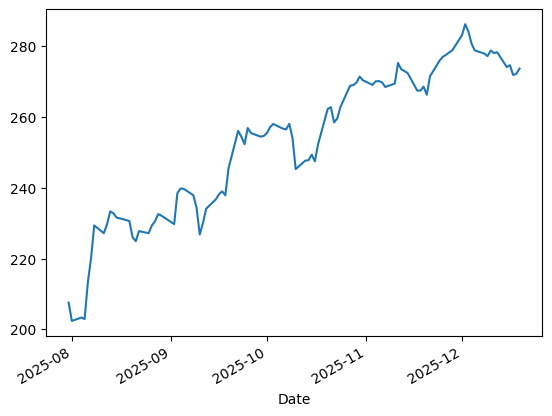

In [7]:
df["Close"].plot()

In [11]:
df["Return"]=df["Close"].pct_change()

In [12]:
df["MA_5"]=df["Close"].rolling(5).mean()

In [13]:
df.resample("W").mean()

,Open,High,Low,Close,Volume,Return,MA_5
Date,,,,,,,
2025-08-03,209.67750,211.710000,204.330000,204.9750,92566452.00,-0.025004,NaN
2025-08-10,210.64800,216.090000,209.051000,213.7800,86365256.20,0.025547,209.353333
2025-08-17,231.01000,232.952000,228.489000,230.9060,59062382.20,0.001993,226.342000
2025-08-24,229.07900,230.414000,226.884080,228.0240,38448335.40,-0.003276,230.131600
2025-08-31,229.05800,231.296000,227.977000,230.3320,38862178.00,0.003830,228.403600
2025-09-07,236.22625,237.729975,234.140025,236.9150,53139295.00,0.008196,233.503500
2025-09-14,232.91600,235.262100,230.264000,232.6240,60957403.40,-0.004560,235.442400
2025-09-21,238.86800,241.402000,237.188840,239.4440,72123906.00,0.009655,235.545200
2025-09-28,253.33900,256.898000,251.646400,255.0300,61874929.20,0.008181,249.440800


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 100 entries, 2025-07-31 to 2025-12-19
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    100 non-null    float64
 1   High    100 non-null    float64
 2   Low     100 non-null    float64
 3   Close   100 non-null    float64
 4   Volume  100 non-null    int64  
 5   Return  99 non-null     float64
 6   MA_5    96 non-null     float64
dtypes: float64(6), int64(1)
memory usage: 6.2 KB


In [15]:
df.isna().sum()

Open      0
High      0
Low       0
Close     0
Volume    0
Return    1
MA_5      4
dtype: int64

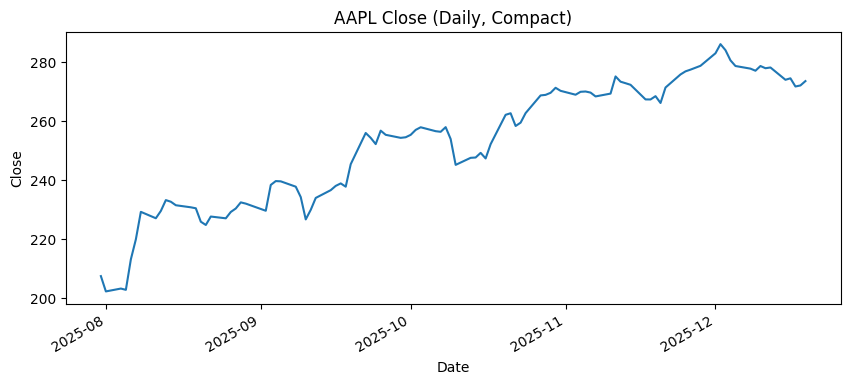

In [16]:
df["Close"].plot(figsize=(10,4), title="AAPL Close (Daily, Compact)")
plt.xlabel("Date")
plt.ylabel("Close")
plt.show()

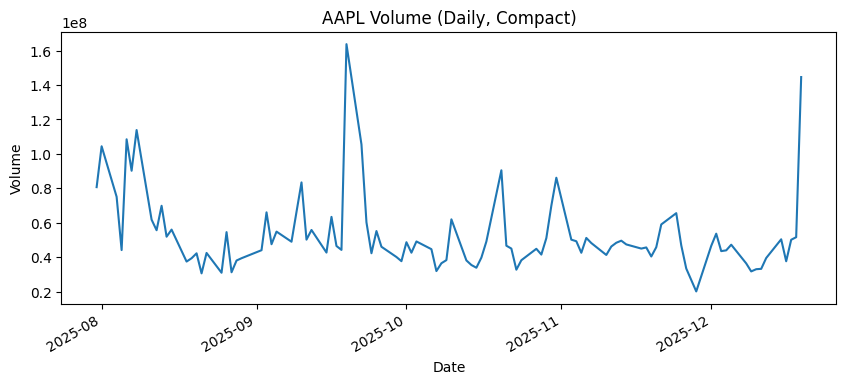

In [ ]:
df["Volume"].plot(figsize=(10,4), title="AAPL Volume (Daily, Compact)")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.show()

In [18]:
df["Return"]=df["Close"].pct_change()
df[["Close","Return"]]. head(10)

,Close,Return
Date,,
2025-07-31,207.57,NaN
2025-08-01,202.38,-0.025004
2025-08-04,203.35,0.004793
2025-08-05,202.92,-0.002115
2025-08-06,213.25,0.050907
2025-08-07,220.03,0.031794
2025-08-08,229.35,0.042358
2025-08-11,227.18,-0.009462
2025-08-12,229.65,0.010872


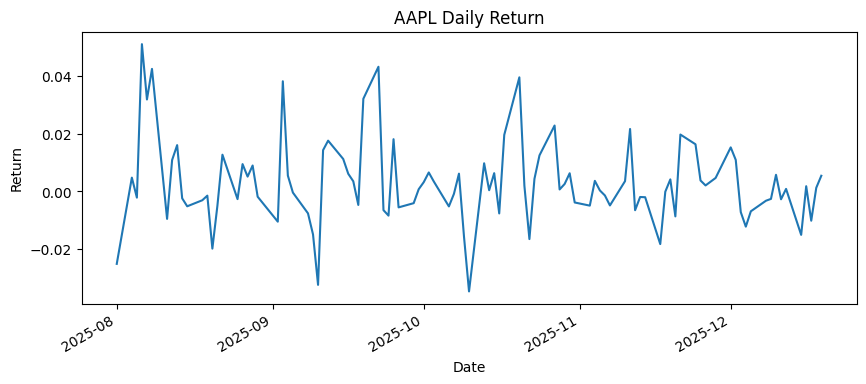

In [19]:
df["Return"].plot(figsize=(10,4), title="AAPL Daily Return")
plt.xlabel("Date")
plt.ylabel("Return")
plt.show()

In [20]:
df["MA_5"]=df["Close"].rolling(5).mean()
df["STD_5"]=df["Close"].rolling(5).std()
df[["Close","MA_5","STD_5"]].tail(10)

,Close,MA_5,STD_5
Date,,,
2025-12-08,277.89,281.542,3.538371
2025-12-09,277.18,279.740,2.795863
2025-12-10,278.78,278.666,1.320371
2025-12-11,278.03,278.132,0.673625
2025-12-12,278.28,278.032,0.584611
2025-12-15,274.11,277.276,1.862211
2025-12-16,274.61,276.762,2.216342
2025-12-17,271.84,275.374,2.746348
2025-12-18,272.19,274.206,2.570609


In [21]:
weekly=df.resample("W").agg({"Close":"last", "Volume":sum})
weekly.head()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_21600\3303139690.py:1: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  weekly=df.resample("W").agg({"Close":"last", "Volume":sum})


,Close,Volume
Date,,
2025-08-03,202.38,185132904
2025-08-10,229.35,431826281
2025-08-17,231.59,295311911
2025-08-24,227.76,192241677
2025-08-31,232.14,194310890


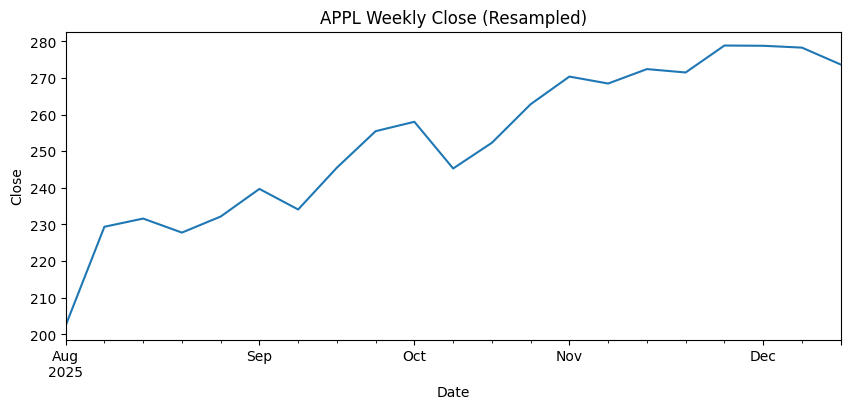

In [22]:
weekly["Close"].plot(figsize=(10,4), title="APPL Weekly Close (Resampled)")
plt.xlabel("Date")
plt.ylabel("Close")
plt.show()